In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
import datetime

pd.set_option('display.max_rows', 500)

In [2]:
# hs=pd.read_csv('test.csv', header=None)
# hs=pd.read_fwf('test.csv', header=None,delimiter=',')
hs = pd.read_csv('test.csv', usecols=[0,1,2,3,4,5], names = ['ts','dir','addr','type','len','val'])

In [3]:
now=np.datetime64(datetime.datetime.now(), 'ns')

In [4]:
def convert_ts(ts):
    return now+np.timedelta64(ts*1000, 'ns')

In [5]:
hs['ts'] = hs['ts'].apply(convert_ts)

In [6]:
hs[hs['dir']=='<']['type'].value_counts().sort_index()

type
14      407
3A      487
8     12152
Name: count, dtype: int64

In [7]:
hs['delta'] = (hs['ts'] - hs['ts'].shift()).astype(int)

In [8]:
hs[10000:10100]

,ts,dir,addr,type,len,val,delta
10000,2024-11-01 14:21:03.757571,>,C8,16,24.0,894.0,2257000
10001,2024-11-01 14:21:03.761571,>,C8,16,24.0,895.0,4000000
10002,2024-11-01 14:21:03.763321,<,EA,8,10.0,891.0,1750000
10003,2024-11-01 14:21:03.765569,>,C8,16,24.0,896.0,2248000
10004,2024-11-01 14:21:03.769567,>,C8,16,24.0,897.0,3998000
10005,2024-11-01 14:21:03.771336,<,EA,8,10.0,895.0,1769000
10006,2024-11-01 14:21:03.773564,>,C8,16,24.0,898.0,2228000
10007,2024-11-01 14:21:03.777564,>,C8,16,24.0,899.0,4000000
10008,2024-11-01 14:21:03.779324,<,EA,8,10.0,896.0,1760000
10009,2024-11-01 14:21:03.781565,>,C8,16,24.0,900.0,2241000


In [9]:
crsf_tel = hs[(hs['addr']=='EA') & (hs['type']=='8')].copy()
crsf_tel['rts'] =  crsf_tel['ts']

In [10]:
crsf_chan = hs[(hs['addr']=='C8') & (hs['type']=='16')].copy()

In [11]:
crsf_chan.info()

<class 'pandas.core.frame.DataFrame'>
Index: 24417 entries, 0 to 37462
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   ts      24417 non-null  datetime64[ns]
 1   dir     24417 non-null  object        
 2   addr    24417 non-null  object        
 3   type    24417 non-null  object        
 4   len     24417 non-null  float64       
 5   val     24417 non-null  float64       
 6   delta   24417 non-null  int64         
dtypes: datetime64[ns](1), float64(2), int64(1), object(3)
memory usage: 1.5+ MB


In [12]:
crsf_tel['delta'] = (crsf_tel['ts'] - crsf_tel['ts'].shift()).dropna().astype(int)/1000
crsf_chan['delta'] = (crsf_chan['ts'] - crsf_chan['ts'].shift()).dropna().astype(int)/1000

In [13]:
crsf_merged = pd.merge_asof(crsf_chan, crsf_tel, on='ts', by='val', tolerance=pd.Timedelta("100ms"), direction='nearest').dropna()

In [14]:
crsf_merged['delta'] = (crsf_merged['rts']  - crsf_merged['ts']).astype(int)/1000

In [20]:
crsf_merged['skip'] = crsf_merged['val'] - crsf_merged['val'].shift() 

In [22]:
crsf_merged.skip.value_counts()

skip
 2.0       4571
 1.0       4486
 3.0       1570
 4.0       1507
-1637.0      15
Name: count, dtype: int64

In [16]:
# crsf_tel['val'].value_counts().sort_index()

<Axes: xlabel='delta', ylabel='Count'>

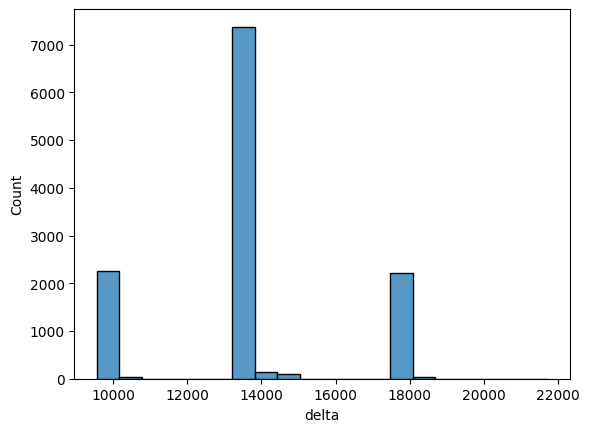

In [17]:
sns.histplot(data=crsf_merged, x='delta', bins=20)

<Axes: xlabel='ts', ylabel='delta'>

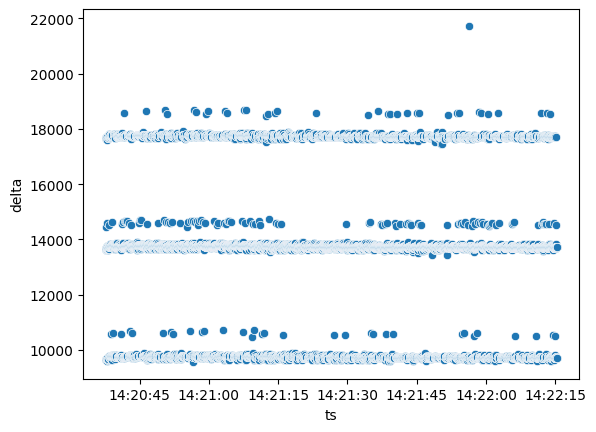

In [18]:
sns.scatterplot(data=crsf_merged, x='ts', y='delta')